In [2]:
import os
import numpy as np

from PIL import Image

import matplotlib.pyplot as plt

from random import randint

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.layers import (
    Conv2D,
    AvgPool2D,
    BatchNormalization,
    Dropout,
    Flatten,
    Dense
)

from tensorflow.keras.models import Sequential

In [3]:
img_gen = ImageDataGenerator(
    rescale=1./255
)

In [4]:
train_loader = img_gen.flow_from_directory(
    directory="/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train",
    target_size=(128, 128),
    batch_size=50,
    seed=42
)

Found 14034 images belonging to 6 classes.


In [5]:
test_loader = img_gen.flow_from_directory(
    directory="/kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test",
    target_size=(128, 128),
    batch_size=50,
    seed=42
)

Found 3000 images belonging to 6 classes.


In [6]:
train_loader.class_indices

{'buildings': 0,
 'forest': 1,
 'glacier': 2,
 'mountain': 3,
 'sea': 4,
 'street': 5}

In [7]:
idx_to_classes = {
    val: key
    for key, val in dict(train_loader.class_indices).items()
}

idx_to_classes

{0: 'buildings',
 1: 'forest',
 2: 'glacier',
 3: 'mountain',
 4: 'sea',
 5: 'street'}

In [8]:
model = Sequential()

In [9]:
# Convolution 1

model.add(
    Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        input_shape=(128, 128, 3)
    )
)

model.add(
    AvgPool2D(
        pool_size=(3, 3)
    )
)

model.add(
    BatchNormalization()
)

model.add(
    Dropout(0.3)
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1791050948.891898      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791050948.895900      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [10]:
# Convolution 2

model.add(
    Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu"
    )
)

model.add(
    AvgPool2D(
        pool_size=(3, 3)
    )
)

model.add(
    BatchNormalization()
)

model.add(
    Dropout(0.3)
)

In [11]:
# Flatten & Linear Fully Connected Layers

model.add(
    Flatten()
)

model.add(
    Dense(
        32,
        activation="relu"
    )
)

model.add(
    Dropout(0.3)
)

model.add(
    Dense(
        6,
        activation="softmax"
    )
)

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 42, 42, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 42, 42, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 42, 42, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 40, 40, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 13, 13, 64)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       346,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 366,118 (1.40 MB)

 Trainable params: 365,926 (1.40 MB)

 Non-trainable params: 192 (768.00 B)

In [13]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [14]:
# Steps

train_steps = len(train_loader)
test_steps = len(test_loader)

print("Train steps:", train_steps)
print("Test steps:", test_steps)

Train steps: 281
Test steps: 60


In [16]:
train_metrics = model.fit(
    train_loader,
    steps_per_epoch=train_steps,
    epochs=20,
    validation_data=test_loader,
    validation_steps=test_steps
)

Epoch 1/20
281/281 ━━━━━━━━━━━━━━━━━━━━ 41s 147ms/step - accuracy: 0.8306 - loss: 0.4505 - val_accuracy: 0.8093 - val_loss: 0.5848
Epoch 2/20
281/281 ━━━━━━━━━━━━━━━━━━━━ 24s 86ms/step - accuracy: 0.8447 - loss: 0.4184 - val_accuracy: 0.6520 - val_loss: 1.0414
Epoch 3/20
281/281 ━━━━━━━━━━━━━━━━━━━━ 24s 87ms/step - accuracy: 0.8452 - loss: 0.3994 - val_accuracy: 0.8000 - val_loss: 0.6628
Epoch 4/20
281/281 ━━━━━━━━━━━━━━━━━━━━ 25s 88ms/step - accuracy: 0.8585 - loss: 0.3853 - val_accuracy: 0.8120 - val_loss: 0.6271
Epoch 5/20
281/281 ━━━━━━━━━━━━━━━━━━━━ 25s 89ms/step - accuracy: 0.8613 - loss: 0.3681 - val_accuracy: 0.8320 - val_loss: 0.5726
Epoch 6/20
281/281 ━━━━━━━━━━━━━━━━━━━━ 24s 87ms/step - accuracy: 0.8660 - loss: 0.3503 - val_accuracy: 0.8053 - val_loss: 0.6833
Epoch 7/20
281/281 ━━━━━━━━━━━━━━━━━━━━ 24s 85ms/step - accuracy: 0.8680 - loss: 0.3422 - val_accuracy: 0.7483 - val_loss: 1.0094
Epoch 8/20
281/281 ━━━━━━━━━━━━━━━━━━━━ 24s 87ms/step - accuracy: 0.8747 - loss: 0.3215 -

In [17]:
train_loss = train_metrics.history["loss"]
train_accuracy = train_metrics.history["accuracy"]

test_loss = train_metrics.history["val_loss"]
test_accuracy = train_metrics.history["val_accuracy"]

In [18]:
print(len(train_loss))
print(len(train_accuracy))
print(len(test_loss))
print(len(test_accuracy))

20
20
20
20


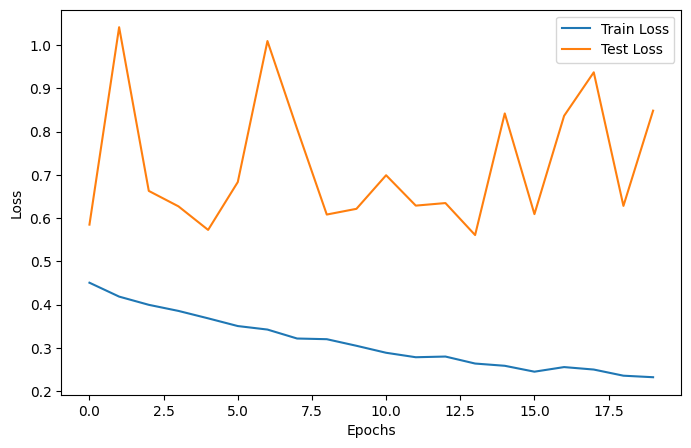

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(range(20), train_loss, label="Train Loss")
plt.plot(range(20), test_loss, label="Test Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

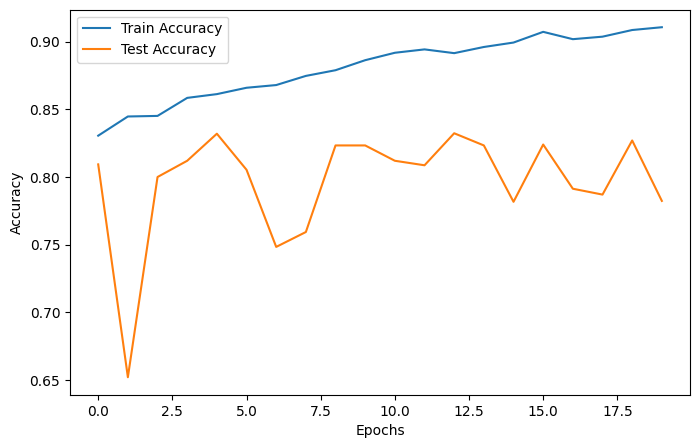

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(range(20), train_accuracy, label="Train Accuracy")
plt.plot(range(20), test_accuracy, label="Test Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [21]:
pred_list = [
    f"/kaggle/input/datasets/puneet6060/intel-image-classification/seg_pred/seg_pred/{i}"
    for i in os.listdir(
        "/kaggle/input/datasets/puneet6060/intel-image-classification/seg_pred/seg_pred"
    )
]

print("Total prediction images:", len(pred_list))

Total prediction images: 7301


In [22]:
from sklearn.metrics import classification_report

test_loader.reset()

predictions = model.predict(test_loader)
y_pred = np.argmax(predictions, axis=1)
y_true = test_loader.classes

print(classification_report(
    y_true,
    y_pred,
    target_names=list(test_loader.class_indices.keys())
))

60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step
              precision    recall  f1-score   support

   buildings       0.15      0.13      0.14       437
      forest       0.17      0.16      0.17       474
     glacier       0.19      0.13      0.15       553
    mountain       0.17      0.14      0.15       525
         sea       0.15      0.25      0.19       510
      street       0.16      0.17      0.17       501

    accuracy                           0.16      3000
   macro avg       0.17      0.16      0.16      3000
weighted avg       0.17      0.16      0.16      3000



In [23]:
test_loader_eval = img_gen.flow_from_directory(
    directory="/kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test",
    target_size=(128, 128),
    batch_size=50,
    class_mode="categorical",
    shuffle=False
)

Found 3000 images belonging to 6 classes.


In [24]:
test_loader_eval.reset()

predictions = model.predict(test_loader_eval)

y_pred = np.argmax(predictions, axis=1)
y_true = test_loader_eval.classes

print("Predicted samples:", len(y_pred))
print("Actual samples:", len(y_true))

60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step
Predicted samples: 3000
Actual samples: 3000


In [25]:
from sklearn.metrics import classification_report

class_names = list(test_loader_eval.class_indices.keys())

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

   buildings       0.89      0.74      0.81       437
      forest       0.97      0.93      0.95       474
     glacier       0.87      0.57      0.69       553
    mountain       0.78      0.64      0.70       525
         sea       0.58      0.95      0.72       510
      street       0.81      0.89      0.85       501

    accuracy                           0.78      3000
   macro avg       0.82      0.79      0.79      3000
weighted avg       0.81      0.78      0.78      3000



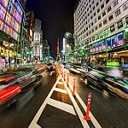

Model Prediction: street


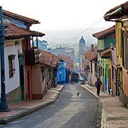

Model Prediction: street


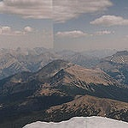

Model Prediction: sea


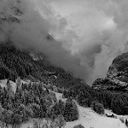

Model Prediction: sea


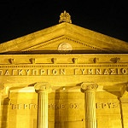

Model Prediction: buildings


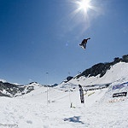

Model Prediction: glacier


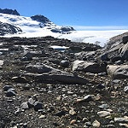

Model Prediction: sea


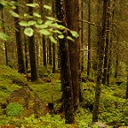

Model Prediction: forest


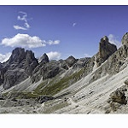

Model Prediction: glacier


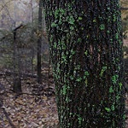

Model Prediction: forest


In [26]:
for i in range(10):

    num = randint(0, len(pred_list) - 1)

    img = Image.open(pred_list[num])

    img = img.resize((128, 128))

    display(img)

    img_arr = np.array(img)

    img_arr = img_arr[np.newaxis, :]

    img_arr = img_arr.astype("float32")

    img_arr = img_gen.standardize(img_arr)

    probability = model(img_arr)

    pred = np.argmax(probability)

    print(
        "Model Prediction:",
        idx_to_classes[pred]
    )

    print("==========================================")